# Audio Driven Hate Speech Detection in Telugu



## Preprocessing of audio modality

In [ ]:
!pip install librosa openpyxl soundfile scikit-learn pandas numpy matplotlib seaborn joblib

In [ ]:
import os
import torch
import librosa
import torchaudio
import numpy as np
import pandas as pd
import torch.nn as nn
import soundfile as sf
#import sounddevice as sd
import torch.optim as optim
import IPython.display as ipd
import matplotlib.pyplot as plt
import zipfile
import os

from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
#from transformers import Speech2TextProcessor, Speech2TextForSequenceClassification
from transformers import AutoConfig, Wav2Vec2Processor, Wav2Vec2Model, Wav2Vec2ForCTC, Wav2Vec2FeatureExtractor

## Extract dataset

In [ ]:
zip_file = "/content/TELUGU DATASET.zip"
extract_path = "/content/telugu_dataset"

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [ ]:
for root, dirs, files in os.walk(extract_path):
    print(root)

/content/telugu_dataset
/content/telugu_dataset/TELUGU DATASET
/content/telugu_dataset/TELUGU DATASET/TE
/content/telugu_dataset/TELUGU DATASET/TE/Hate
/content/telugu_dataset/TELUGU DATASET/TE/Hate/Gender
/content/telugu_dataset/TELUGU DATASET/TE/Hate/Political
/content/telugu_dataset/TELUGU DATASET/TE/Hate/Religion
/content/telugu_dataset/TELUGU DATASET/TE/Hate/Character Assassination
/content/telugu_dataset/TELUGU DATASET/TE/Non Hate
/content/telugu_dataset/TELUGU DATASET/TE/Excel


In [ ]:
dataset_dir = "/content/telugu_dataset/TELUGU DATASET/TE"

hate_dir = os.path.join(dataset_dir, "Hate")
non_hate_dir = os.path.join(dataset_dir, "Non-Hate")

print("Hate directory:", hate_dir)
print("Non-Hate directory:", non_hate_dir)

Hate directory: /content/telugu_dataset/TELUGU DATASET/TE/Hate
Non-Hate directory: /content/telugu_dataset/TELUGU DATASET/TE/Non-Hate


In [ ]:
# check the audio files
print("Hate files:")
print(os.listdir(hate_dir)[:10])

Hate files:
['Gender', 'Political', 'Religion', 'Character Assassination']


## Extracting the Meta Data from Audio Files

This step extracts metadata from the audio file names and folder structure, such as the hate/non-hate label, hate subtype, gender, and file path, and organizes them into a Pandas DataFrame for further preprocessing and model training

In [ ]:
# Initialize an empty list to store the file information
data = []

# Iterate through the "Hate" and "Non Hate" folders
for label in ["Hate", "Non Hate"]:
    folder_path = os.path.join(dataset_dir, label)

    # For "Hate" category, also iterate through the subfolders
    if label == "Hate":
        for sub_category in ["Character Assassination", "Gender", "Political", "Religion"]:
            sub_folder_path = os.path.join(folder_path, sub_category)
            for file_name in os.listdir(sub_folder_path):
                # Parse details from the file name
                parts = file_name.split('_')
                hate_or_non_hate = "Hate"
                sub_category_code = parts[3]  # e.g., C, G, P, or R
                gender = parts[4]

                # Store details in a dictionary
                file_info = {
                    "File Name": file_name,
                    "Hate or Non Hate": hate_or_non_hate,
                    "Sub Category": sub_category_code,
                    "Gender": gender,
                    "File Path": os.path.join(sub_folder_path, file_name)
                }
                data.append(file_info)
    else:
        # For "Non Hate" files, only iterate through the files directly
        for file_name in os.listdir(folder_path):
            parts = file_name.split('_')
            hate_or_non_hate = "Non Hate"
            sub_category_code = "NH"  # No sub-category for non-hate files
            gender = parts[4]

            # Store details in a dictionary
            file_info = {
                "File Name": file_name,
                "Hate or Non Hate": hate_or_non_hate,
                "Sub Category": sub_category_code,
                "Gender": gender,
                "File Path": os.path.join(folder_path, file_name)
            }
            data.append(file_info)

# Create a DataFrame from the collected data
df = pd.DataFrame(data)

In [ ]:
print(df)

                     File Name Hate or Non Hate Sub Category Gender  \
0     H_TE_003_C_M_030_002.mp3             Hate            C      M   
1     H_TE_003_C_F_021_001.mp3             Hate            C      F   
2     H_TE_003_C_F_021_002.mp3             Hate            C      F   
3     H_TE_003_C_M_020_004.mp3             Hate            C      M   
4     H_TE_003_C_M_027_002.mp3             Hate            C      M   
..                         ...              ...          ...    ...   
596  NH_TE_001_N_M_016_001.mp3         Non Hate           NH      M   
597  NH_TE_001_N_F_008_001.mp3         Non Hate           NH      F   
598  NH_TE_002_N_F_002_002.mp3         Non Hate           NH      F   
599  NH_TE_002_N_F_004_001.mp3         Non Hate           NH      F   
600  NH_TE_001_N_M_018_001.mp3         Non Hate           NH      M   

                                             File Path  
0    /content/telugu_dataset/TELUGU DATASET/TE/Hate...  
1    /content/telugu_dataset/TELU

## Distribution of Hate & Non Hate Samples

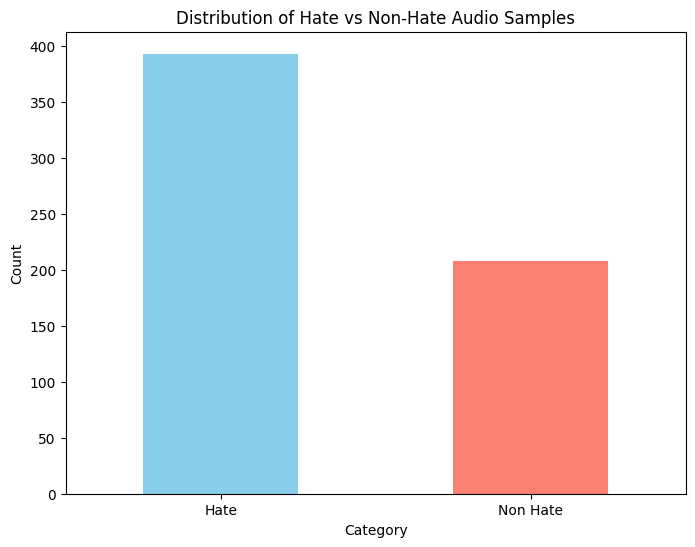

In [ ]:
# Get the count of each category (Hate vs Non Hate)
hate_non_hate_counts = df["Hate or Non Hate"].value_counts()

# Plot the distribution as a bar graph
plt.figure(figsize=(8, 6))
hate_non_hate_counts.plot(kind='bar', color=['skyblue', 'salmon'])
plt.title('Distribution of Hate vs Non-Hate Audio Samples')
plt.xlabel('Category')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

## Distribution of Samples per Category

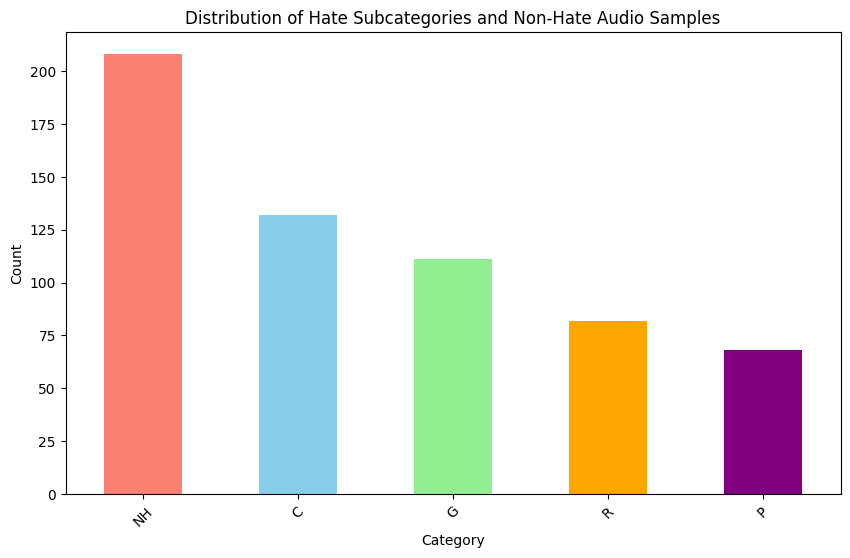

In [ ]:
# Replace NaN in "Sub Category" with "Non Hate" for easier grouping
df['Sub Category'] = df['Sub Category'].fillna('Non Hate')

# Get the count of each subcategory (including Non Hate)
subcategory_counts = df['Sub Category'].value_counts()

# Plot the distribution as a bar graph
plt.figure(figsize=(10, 6))
subcategory_counts.plot(kind='bar', color=['salmon', 'skyblue', 'lightgreen', 'orange', 'purple'])
plt.title('Distribution of Hate Subcategories and Non-Hate Audio Samples')
plt.xlabel('Category')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

## Gender Samples Distribution

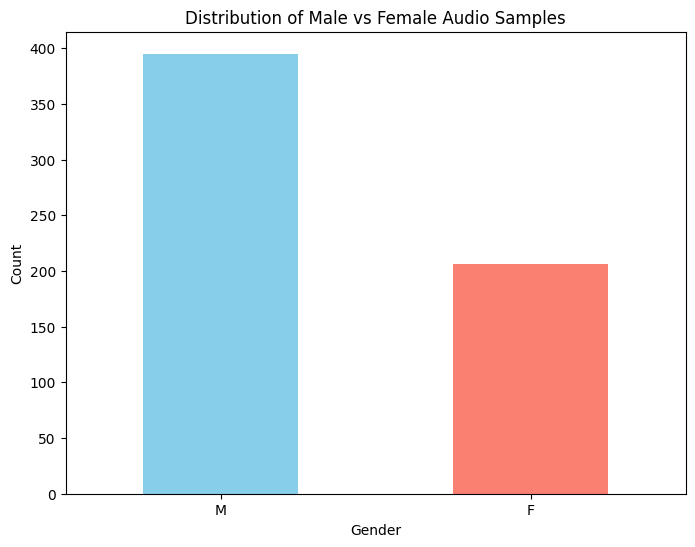

In [ ]:
# Get the count of each category (Hate vs Non Hate)
hate_non_hate_counts = df["Gender"].value_counts()

# Plot the distribution as a bar graph
plt.figure(figsize=(8, 6))
hate_non_hate_counts.plot(kind='bar', color=['skyblue', 'salmon'])
plt.title('Distribution of Male vs Female Audio Samples')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

## Duration of Audio Files per Category

In [ ]:
def get_audio_duration(file_path):
    audio, sr = librosa.load(file_path, sr=None)
    return librosa.get_duration(y=audio, sr=sr)

df['Duration'] = df['File Path'].apply(get_audio_duration)

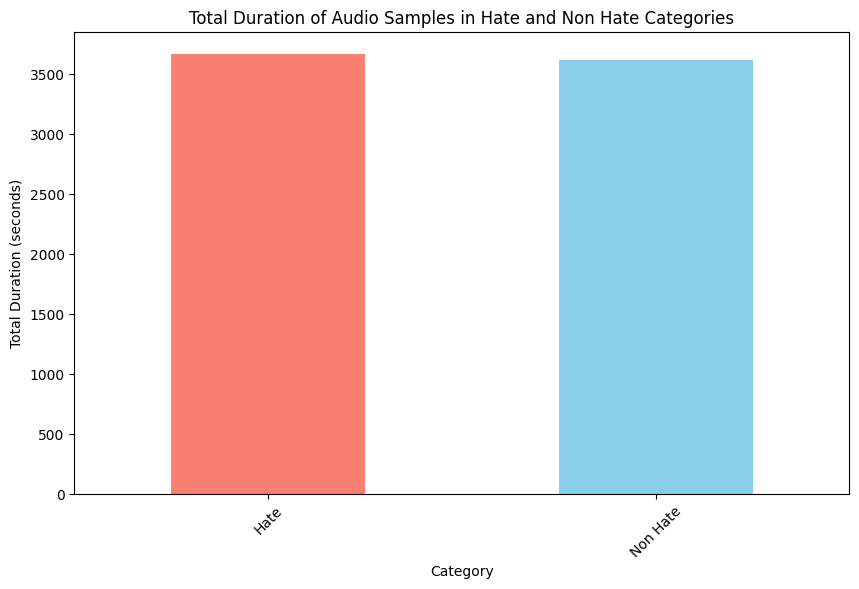

In [ ]:
total_durations_HateorNonHate = df.groupby('Hate or Non Hate')['Duration'].sum()

# Plot the total duration for each category
plt.figure(figsize=(10, 6))
total_durations_HateorNonHate.plot(kind='bar', color=['salmon', 'skyblue'])
plt.title('Total Duration of Audio Samples in Hate and Non Hate Categories')
plt.xlabel('Category')
plt.ylabel('Total Duration (seconds)')
plt.xticks(rotation=45)
plt.show()

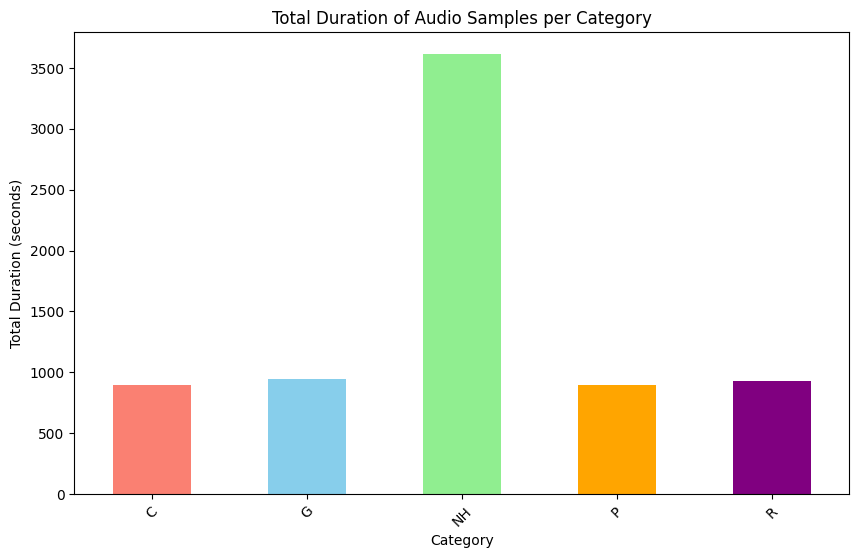

In [ ]:
total_durations_per_category = df.groupby('Sub Category')['Duration'].sum()

# Plot the total duration for each category
plt.figure(figsize=(10, 6))
total_durations_per_category.plot(kind='bar', color=['salmon', 'skyblue', 'lightgreen', 'orange', 'purple'])
plt.title('Total Duration of Audio Samples per Category')
plt.xlabel('Category')
plt.ylabel('Total Duration (seconds)')
plt.xticks(rotation=45)
plt.show()

In [ ]:
print(total_durations_per_category)

Sub Category
C      894.518980
G      945.162290
NH    3612.558844
P      894.390023
R      929.868413
Name: Duration, dtype: float64


## Outliers detection based on Duration

Duration analysis is performed as a data-quality and preprocessing step to identify unusually short or long audio clips and to determine an appropriate duration for padding and truncation before model training

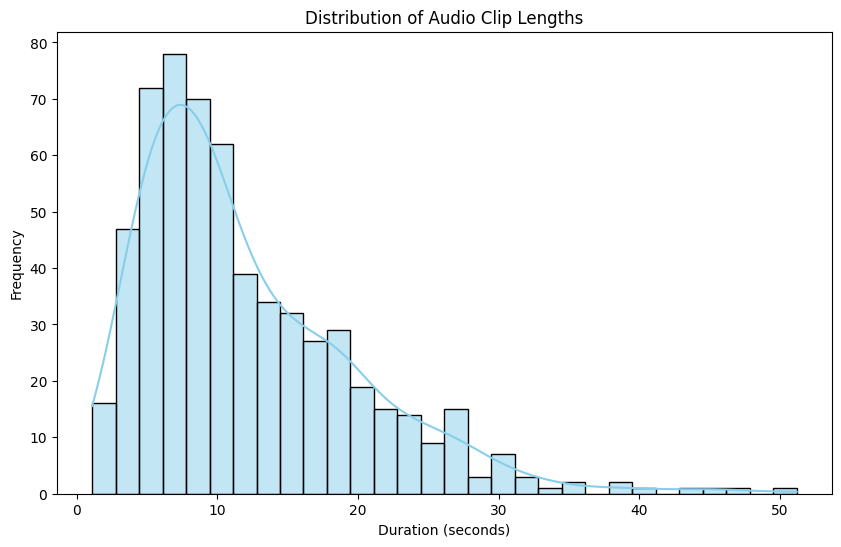

Outliers in Duration (in seconds):
                      File Name   Duration Sub Category
399   NH_TE_002_N_F_005_002.mp3  45.357937           NH
415   NH_TE_003_N_F_009_001.mp3  28.473469           NH
419   NH_TE_002_N_F_005_003.mp3  32.633764           NH
425   NH_TE_001_N_M_039_001.mp3  29.650000           NH
430   NH_TE_001_N_M_020_001.mp3  38.220000           NH
434   NH_TE_002_N_F_005_001.mp3  51.196100           NH
443   NH_TE_002_N_F_001_001.mp3  32.197574           NH
465   NH_TE_002_N_F_003_001.mp3  38.593424           NH
487   NH_TE_002_N_F_009_001.mp3  33.802154           NH
493  NH_TE_002_N_M_0011_002.mp3  28.302132           NH
501   NH_TE_002_N_F_008_001.mp3  40.829501           NH
510   NH_TE_002_N_F_006_001.mp3  32.523356           NH
513  NH_TE_002_N_F_0010_003.mp3  30.184127           NH
520   NH_TE_002_N_M_007_001.mp3  34.827007           NH
525   NH_TE_002_N_F_005_004.mp3  35.777392           NH
546   NH_TE_001_N_M_040_006.mp3  29.000000           NH
549   NH_TE_0

In [ ]:
import seaborn as sns

# Plot the overall distribution of clip lengths
plt.figure(figsize=(10, 6))
sns.histplot(df['Duration'], bins=30, kde=True, color='skyblue')
plt.title('Distribution of Audio Clip Lengths')
plt.xlabel('Duration (seconds)')
plt.ylabel('Frequency')
plt.show()

# Calculate basic statistics for duration
mean_duration = df['Duration'].mean()
std_duration = df['Duration'].std()

# Define outlier thresholds (e.g., mean ± 2*std)
lower_threshold = mean_duration - 2 * std_duration
upper_threshold = mean_duration + 2 * std_duration

# Identify outliers
outliers = df[(df['Duration'] < lower_threshold) | (df['Duration'] > upper_threshold)]
print("Outliers in Duration (in seconds):")
print(outliers[['File Name', 'Duration', 'Sub Category']])

# Suggested duration range based on the data (e.g., 5th to 95th percentile)
suggested_min, suggested_max = np.percentile(df['Duration'], [5, 95])
print(f"Suggested duration range for padding/truncation: {suggested_min:.2f} - {suggested_max:.2f} seconds")

## Checking for Sampling Rate

Sampling rate is the number of audio samples taken per second to represent a continuous sound signal digitally. It is measured in Hertz

In [ ]:
def check_sampling_rate(file):
    y, sr = librosa.load(file, sr=None)
    return sr

df['sampling_rate'] = df['File Path'].apply(check_sampling_rate)
print(df['sampling_rate'].value_counts())

sampling_rate
44100    600
48000      1
Name: count, dtype: int64


## Resampling the audio files to 16000Hz

First, we check the original sampling rates of all audio files. Since most files are at 44.1 kHz and one file is at 48 kHz, we resample all audio to a common 16 kHz sampling rate. The resampled files are saved separately while preserving the original folder structure, and their new paths are stored in the DataFrame for subsequent processing

In [ ]:
def copy_and_resample_audio(df, input_dir, output_dir, target_sr=16000):

    os.makedirs(output_dir, exist_ok=True)
    resampled_rates = []
    new_file_paths = []

    for index, row in df.iterrows():
        # Get the original file path
        original_file_path = row['File Path']

        # Determine the relative path to maintain the structure
        relative_path = os.path.relpath(original_file_path, input_dir)
        new_file_path = os.path.join(output_dir, relative_path)

        # Create necessary directories for the new file path
        os.makedirs(os.path.dirname(new_file_path), exist_ok=True)

        # Load the original audio file
        original_audio, sr_original = librosa.load(original_file_path, sr=None)

        # Resample the audio
        resampled_audio = librosa.resample(original_audio, orig_sr=sr_original, target_sr=target_sr)

        # Save the resampled audio to the new file path as .mp3
        sf.write(new_file_path, resampled_audio, target_sr, format='MP3')

        # Append the new sampling rate and new file path to their respective lists
        resampled_rates.append(target_sr)
        new_file_paths.append(new_file_path)  # Keep it in .mp3 format

    # Add the new columns to the DataFrame
    df['Resampled Sampling Rate'] = resampled_rates
    df['New File Path'] = new_file_paths

    return df

input_directory = '/content/telugu_dataset/TELUGU DATASET/TE'
output_directory = '/content/resampled_audios'

new_df = copy_and_resample_audio(df, input_directory, output_directory)

In [ ]:
print(new_df)

                     File Name Hate or Non Hate Sub Category Gender  \
0     H_TE_003_C_M_030_002.mp3             Hate            C      M   
1     H_TE_003_C_F_021_001.mp3             Hate            C      F   
2     H_TE_003_C_F_021_002.mp3             Hate            C      F   
3     H_TE_003_C_M_020_004.mp3             Hate            C      M   
4     H_TE_003_C_M_027_002.mp3             Hate            C      M   
..                         ...              ...          ...    ...   
596  NH_TE_001_N_M_016_001.mp3         Non Hate           NH      M   
597  NH_TE_001_N_F_008_001.mp3         Non Hate           NH      F   
598  NH_TE_002_N_F_002_002.mp3         Non Hate           NH      F   
599  NH_TE_002_N_F_004_001.mp3         Non Hate           NH      F   
600  NH_TE_001_N_M_018_001.mp3         Non Hate           NH      M   

                                             File Path   Duration  \
0    /content/telugu_dataset/TELUGU DATASET/TE/Hate...   4.048980   
1    /con

## Generating Train and Test data

In [ ]:
new_df.to_csv('preprocessed_data.csv', index=False)
print(new_df.columns.tolist())

['File Name', 'Hate or Non Hate', 'Sub Category', 'Gender', 'File Path', 'Duration', 'sampling_rate', 'Resampled Sampling Rate', 'New File Path']


In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Get unique categories in 'Sub Category'
categories = new_df['Sub Category'].unique()

# Calculate the class weights
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=categories,
    y=new_df['Sub Category']
)

# Map class weights to each category
class_weight_dict = {category: weight for category, weight in zip(categories, class_weights)}

print("Class weights based on 'Sub Category':")
print(class_weight_dict)

Class weights based on 'Sub Category':
{'C': np.float64(0.9106060606060606), 'G': np.float64(1.082882882882883), 'P': np.float64(1.7676470588235293), 'R': np.float64(1.4658536585365853), 'NH': np.float64(0.5778846153846153)}


In [ ]:
# Splitting the dataset into training and testing sets
X = df[['File Name', 'New File Path', 'Duration']]
y = df[['Hate or Non Hate', 'Sub Category']]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Data Augmentation on Training Set

Creating additional training examples from our existing training data by making small changes to the original data


3 Augmentation techniques used:
- Time shifting - This shifts the audio waveform slightly forward or backward.
- time stretching - This changes the speed of the audio without fundamentally changing its content.
- noise addition


In [ ]:
y_train['Sub Category'].value_counts()

,count
Sub Category,
NH,166
C,104
G,86
R,68
P,56


In [ ]:
import random

# Function to apply time shifting
def time_shift(audio, max_shift=0.5):
    shift_samples = int(random.uniform(-max_shift, max_shift) * len(audio))
    return np.roll(audio, shift_samples)

# Function to apply noise addition
def add_noise(audio, noise_factor=0.005):
    noise = noise_factor * np.random.randn(len(audio))
    return audio + noise

# New function to apply time-stretching
def time_stretch(audio, rate=1.2):
    return librosa.effects.time_stretch(audio, rate=rate)

# Augmentation function that applies one of the three techniques randomly
def augment_audio(audio, sr):
    augmentation_choice = random.choice(['time_shift', 'time_stretch', 'add_noise'])

    if augmentation_choice == 'time_shift':
        return time_shift(audio)
    elif augmentation_choice == 'time_stretch':
        return time_stretch(audio)
    elif augmentation_choice == 'add_noise':
        return add_noise(audio)

In [ ]:
# Function to apply augmentation to audio and save the samples
def augment_and_save_samples(audio_df, labels_df, output_dir, target_count):
    os.makedirs(output_dir, exist_ok=True)
    augmented_audio_data = []
    augmented_labels_data = []

    # Merge audio information with corresponding labels (Sub Category) from y_train
    merged_df = pd.concat([audio_df, labels_df], axis=1)

    # Track the count of samples per category
    category_counts = merged_df['Sub Category'].value_counts().to_dict()

    for sub_category, count in category_counts.items():
        if count >= target_count:
            print(f"Category '{sub_category}' already has {count} samples, skipping augmentation.")
            continue  # Skip augmentation if the category already has enough samples

        print(f"Starting augmentation for category '{sub_category}' (Current count: {count})")

        # Filter the dataframe for the current sub-category
        category_data = merged_df[merged_df['Sub Category'] == sub_category]

        # Calculate how many samples are needed to reach the target count
        samples_needed = target_count - count
        augmented_samples = 0  # Track number of augmented samples

        # Keep augmenting until we reach the target count
        while augmented_samples < samples_needed:
            for index, row in category_data.iterrows():
                file_path = row['New File Path']
                original_file_name = row['File Name']
                sub_category = row['Sub Category']

                # Load the audio file
                audio, sr = librosa.load(file_path, sr=None)

                # Apply random augmentation
                augmented_audio = augment_audio(audio, sr)

                # Create new file name for the augmented sample (original name + '_type_of_augmentation')
                augmentation_type = random.choice(['time_shift', 'time_stretch', 'add_noise'])
                new_file_name = f"{original_file_name}_{augmentation_type}.mp3"
                new_file_path = os.path.join(output_dir, new_file_name)

                # Save the augmented audio file
                sf.write(new_file_path, augmented_audio, sr, format='MP3')

                # Calculate new duration
                new_duration = librosa.get_duration(y=augmented_audio, sr=sr)

                # Store the augmented audio-related information
                augmented_audio_data.append({
                    "File Name": new_file_name,
                    "New File Path": new_file_path,
                    "Duration": new_duration
                })

                # Store the augmented label information (using the merged dataframe for label lookup)
                augmented_labels_data.append({
                    "Hate or Non Hate": row['Hate or Non Hate'],
                    "Sub Category": sub_category
                })

                # Increment the augmented samples counter
                augmented_samples += 1

                # If we reach the required number of samples, break the loop
                if augmented_samples >= samples_needed:
                    break

            # Update the count for the current sub-category
            category_counts[sub_category] = count + augmented_samples

            print(f"Category '{sub_category}' now has {count + augmented_samples} samples after augmentation.")

            # Exit the loop if we have reached the required number of samples
            if augmented_samples >= samples_needed:
                break

    # Create separate dataframes for augmented audio and labels
    augmented_audio_df = pd.DataFrame(augmented_audio_data)
    augmented_labels_df = pd.DataFrame(augmented_labels_data)

    return augmented_audio_df, augmented_labels_df

In [ ]:
# Folder to save augmented audio files
augmented_output_dir = '/content/augmented_audios'

# Highest class count in the training set
target_count = 166

# Perform data augmentation
augmented_audio_df, augmented_labels_df = augment_and_save_samples(
    X_train,
    y_train,
    augmented_output_dir,
    target_count=target_count
)

# Append augmented samples to the original training data
X_train_augmented = pd.concat(
    [X_train, augmented_audio_df],
    ignore_index=True
)

# Append augmented labels as well
y_train_augmented = pd.concat(
    [y_train, augmented_labels_df],
    ignore_index=True
)

Category 'NH' already has 166 samples, skipping augmentation.
Starting augmentation for category 'C' (Current count: 104)
Category 'C' now has 166 samples after augmentation.
Starting augmentation for category 'G' (Current count: 86)
Category 'G' now has 166 samples after augmentation.
Starting augmentation for category 'R' (Current count: 68)
Category 'R' now has 136 samples after augmentation.
Category 'R' now has 166 samples after augmentation.
Starting augmentation for category 'P' (Current count: 56)
Category 'P' now has 112 samples after augmentation.
Category 'P' now has 166 samples after augmentation.


In [ ]:
print(len(X_train))
print(len(X_train_augmented))

480
830


In [ ]:
print(X_train_augmented)

                                     File Name  \
0                     H_TE_003_C_F_005_001.mp3   
1                     H_TE_001_R_M_022_002.mp3   
2                    NH_TE_002_N_M_013_001.mp3   
3                     H_TE_002_G_M_002_001.mp3   
4                     H_TE_003_C_M_034_001.mp3   
..                                         ...   
825  H_TE_003_P_M_006_001.mp3_time_stretch.mp3   
826    H_TE_003_P_F_017_002.mp3_time_shift.mp3   
827     H_TE_003_P_M_005_001.mp3_add_noise.mp3   
828     H_TE_003_P_M_003_005.mp3_add_noise.mp3   
829    H_TE_003_P_F_005_002.mp3_time_shift.mp3   

                                         New File Path   Duration  
0    /content/resampled_audios/Hate/Character Assas...   5.616327  
1    /content/resampled_audios/Hate/Religion/H_TE_0...  20.000000  
2    /content/resampled_audios/Non Hate/NH_TE_002_N...  15.072653  
3    /content/resampled_audios/Hate/Gender/H_TE_002...   1.906939  
4    /content/resampled_audios/Hate/Character Assas...  12.

In [ ]:
# Adding binary and multi-class classification labels to X_train and X_test
# Binary label: 'Hate or Non Hate' as 0 (Non Hate) or 1 (Hate)
X_train_augmented['Binary Label'] = y_train_augmented['Hate or Non Hate'].apply(lambda x: 1 if x == 'Hate' else 0)
X_test['Binary Label'] = y_test['Hate or Non Hate'].apply(lambda x: 1 if x == 'Hate' else 0)

# Multi-class label: 'Sub Category' with unique numeric encoding for each category
# Assigning numeric labels to each sub-category for multi-class classification
category_mapping = {category: i for i, category in enumerate(y['Sub Category'].unique())}
X_train_augmented['Multi-class Label'] = y_train_augmented['Sub Category'].map(category_mapping)
X_test['Multi-class Label'] = y_test['Sub Category'].map(category_mapping)

In [ ]:
# Shuffle the training set before saving
X_train_augmented = X_train_augmented.sample(frac=1, random_state=42).reset_index(drop=True)
X_train_augmented.to_csv('train_data.csv', index=False)

# Shuffle the testing set before saving
X_test = X_test.sample(frac=1, random_state=42).reset_index(drop=True)
X_test.to_csv('test_data.csv', index=False)

In [ ]:
data_files = {
    "train": "/content/train_data.csv",
    "test": "/content/test_data.csv",
}

dataset = load_dataset("csv", data_files=data_files)

train_dataset = dataset["train"]
test_dataset = dataset["test"]

# Print the loaded datasets
print(train_dataset)
print(test_dataset)

Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Dataset({
    features: ['File Name', 'New File Path', 'Duration', 'Binary Label', 'Multi-class Label'],
    num_rows: 830
})
Dataset({
    features: ['File Name', 'New File Path', 'Duration', 'Binary Label', 'Multi-class Label'],
    num_rows: 121
})


In [ ]:
input_column = 'New File Path'
output_column_B = 'Binary Label'
output_column_M = 'Multi-class Label'

# we need to distinguish the unique labels in our SER dataset
binary_label_list = train_dataset.unique(output_column_B)
binary_label_list.sort()  # Let's sort it for determinism
num_labels_B = len(binary_label_list)


# we need to distinguish the unique labels in our SER dataset
multi_class_label_list = train_dataset.unique(output_column_M)
multi_class_label_list.sort()  # Let's sort it for determinism
num_labels_M = len(multi_class_label_list)

print(f"A binary classification problem with {num_labels_B} classes: {binary_label_list}")
print(f"A multi-class classification problem with {num_labels_M} classes: {multi_class_label_list}")

A binary classification problem with 2 classes: [0, 1]
A multi-class classification problem with 5 classes: [0, 1, 2, 3, 4]


In [ ]:
print(category_mapping)

{'C': 0, 'G': 1, 'P': 2, 'R': 3, 'NH': 4}


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!cp -r /content/telugu_dataset /content/drive/MyDrive/

In [ ]:
!cp -r /content/augmented_audios /content/drive/MyDrive/